<a href="https://colab.research.google.com/github/Daria720/ML/blob/main/%D0%9B%D0%A010_%D0%9C%D0%9D_%D0%93%D0%BE%D0%BC%D0%BE%D0%BD%D1%8E%D0%BA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Гомонюк Дар'я      
**Група:** 3-10    
**Дата:** 06.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow import keras
import os

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

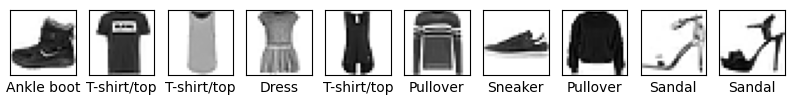

In [3]:
plt.figure(figsize=(10,10))
for i in range(10):
    plt.subplot(1,10,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train = (x_train / 255.0).astype("float32")
x_test  = (x_test  / 255.0).astype("float32")

### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
model = models.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Перший прихований шар на 256 нейронів виділяє основні ознаки з вхідного вектора на 784 елементи, а другий шар на 64 нейрони поступово стискає їх перед виходом. На виході 10 нейронів відповідають 10 класам одягу. Регуляризація Dropout 0.3 вимикає 30% нейронів під час навчання, щоб мережа не перенавчалася та краще узагальнювала дані. Зменшена швидкість навчання 3*10^(-4)для Adam забезпечує плавнішу та стабільнішу сходимість функції втрат без проскакування мінімуму.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

history = model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    callbacks=cb,
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", test_acc)

Epoch 1/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7008 - loss: 0.8665 - val_accuracy: 0.8283 - val_loss: 0.4945 - learning_rate: 3.0000e-04
Epoch 2/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8144 - loss: 0.5438 - val_accuracy: 0.8470 - val_loss: 0.4235 - learning_rate: 3.0000e-04
Epoch 3/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8363 - loss: 0.4714 - val_accuracy: 0.8550 - val_loss: 0.3967 - learning_rate: 3.0000e-04
Epoch 4/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8474 - loss: 0.4342 - val_accuracy: 0.8585 - val_loss: 0.3806 - learning_rate: 3.0000e-04
Epoch 5/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8562 - loss: 0.4054 - val_accuracy: 0.8702 - val_loss: 0.3543 - learning_rate: 3.0000e-04
Epoch 6/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8618 - loss: 0.3851 - val_accuracy: 0.8712 - val_loss: 0.3441 - learning_rate: 3.0000e-04
Epoch 7/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accurac

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 654,176 (2.50 MB)

 Trainable params: 218,058 (851.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 436,118 (1.66 MB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

Mounted at /content/drive


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

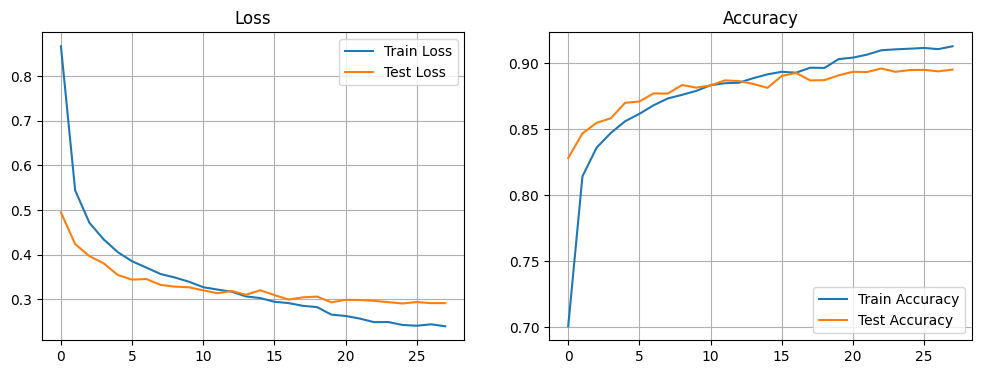

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.title('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Test Accuracy')
plt.title('Accuracy')
plt.grid(True)
plt.legend()

plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
predictions = model.predict(x_test)

predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(y_test, predicted_labels, target_names=class_names))

313/313 - 1s - 2ms/step - accuracy: 0.8888 - loss: 0.3145
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.81      0.81      1000
       Dress       0.88      0.90      0.89      1000
        Coat       0.81      0.81      0.81      1000
      Sandal       0.97      0.96      0.97      1000
       Shirt       0.71      0.70      0.70      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.96      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



Отримане значення accuracy на тестовій вибірці становить 0.8888, що перевищує встановлений поріг 0.87. Це свідчить про високу якість класифікації та успішне навчання моделі без перенавчання.

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

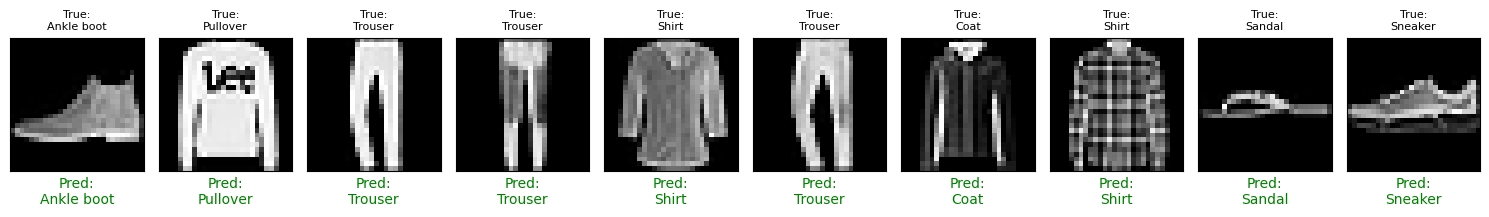

In [11]:
plt.figure(figsize=(15, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_test[i], cmap='gray')
    pred_label = class_names[predicted_labels[i]]
    true_label = class_names[y_test[i]]
    color = 'green' if predicted_labels[i] == y_test[i] else 'red'
    plt.xlabel(f"Pred:\n{pred_label}", color=color)
    plt.title(f"True:\n{true_label}", fontsize=8)

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
 Аналіз класифікаційного звіту показує, що найменшу точність розпізнавання та найбільшу кількість помилок модель припускає на класі Shirt, який мережа найчастіше плутає з іншими схожими типами верхнього одягу через їхню близьку візуальну форму. Найкраще модель класифікує Trouser, Sandal  та Bag. Вимогу щодо мінімальної точності повністю виконано, оскільки отримане значення accuracy (0.8888) перевищує встановлений поріг 0.87.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
!pip install keras-tuner -q

In [13]:
from tensorflow.keras.layers import Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from keras_tuner.tuners import RandomSearch

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow import keras
import os

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(Dense(units=hp.Int('units_' + str(i),
                                     min_value=32,
                                     max_value=512,
                                     step=32),
                        activation='relu',
                        kernel_regularizer=l2(0.001)))
        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer=keras.optimizers.Adam(
        hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_logs',
    project_name='fashion_mnist_classification'
)

### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

tuner.search(x_train, y_train, epochs=50, validation_split=0.1, callbacks=[early_stopping, reduce_lr])

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.get_best_models(num_models=1)[0]

print("Найкращі гіперпараметри:")
print(f"Кількість шарів: {best_hps.get('num_layers')}")
for i in range(best_hps.get('num_layers')):
    print(f"Нейронів у шарі {i+1}: {best_hps.get(f'units_{i}')}")
print(f"Learning rate: {best_hps.get('learning_rate')}\n")

best_model.summary()

history = best_model.fit(
    x_train, y_train,
    epochs=50,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr]
)

Trial 3 Complete [00h 01m 28s]
val_accuracy: 0.7728333473205566

Best val_accuracy So Far: 0.8646666407585144
Total elapsed time: 00h 05m 46s
Найкращі гіперпараметри:
Кількість шарів: 2
Нейронів у шарі 1: 160
Нейронів у шарі 2: 32
Learning rate: 0.001



/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 160)            │       125,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131,082 (512.04 KB)

 Trainable params: 131,082 (512.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8416 - loss: 0.5502 - val_accuracy: 0.8613 - val_loss: 0.4948 - learning_rate: 0.0010
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8445 - loss: 0.5434 - val_accuracy: 0.8553 - val_loss: 0.4997 - learning_rate: 0.0010
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.8462 - loss: 0.5352 - val_accuracy: 0.8563 - val_loss: 0.4860 - learning_rate: 0.0010
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.8462 - loss: 0.5334 - val_accuracy: 0.8663 - val_loss: 0.4704 - learning_rate: 0.0010
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8470 - loss: 0.5317 - val_accuracy: 0.8588 - val_loss: 0.4903 - learning_rate: 0.0010
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8454 - loss: 0.5335 - val_accuracy: 0.8487 - val_loss: 0.5038 - learning_rate: 0.0010
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.844

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8609 - loss: 0.4865
Test accuracy: 0.8608999848365784
Test loss: 0.48651909828186035


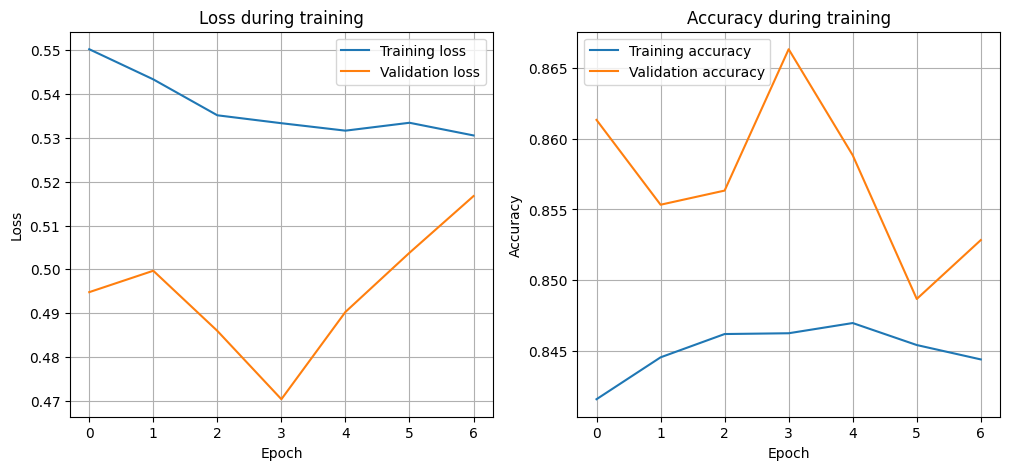

In [18]:
test_loss, test_acc = best_model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)
print('Test loss:', test_loss)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Loss during training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Accuracy during training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 2 |
| Кількість нейронів | 256 та 64 | 160 та 32 |
| Швидкість навчання | 0.0003 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8888 | 0.8609 |
| Втрати на тестовій вибірці (loss) | 0.3145 | 0.4865 |
| Кількість епох навчання | ~10–15 | 7 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?        

Так, у завданні 1 було досягнуто точності accuracy = 0.8888, що повністю відповідає вимозі та перевищує поріг 0.87

2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?

У даному випадку автоматизований пошук не покращив точність на тестовій вибірці. Точність знизилася з 0.8888 до 0.8609, а втрати зросли через занадто велику швидкість навчання та обмежену кількість спроб.

3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?

Найкращою за результатом тюнера виявилася конфігурація з 2 прихованими шарами (160 та 32 нейрони) і learning_rate = 0.001. Результати відрізняються між запусками через випадкову ініціалізацію початкових ваг нейронів, випадковий вибір комбінацій у RandomSearch, а також роботу шарів Dropout.

4. Які класи Fashion MNIST класифікувати найскладніше?

Найскладніше модель класифікує клас Shirt (сорочка), оскільки він має високу візуальну схожість з іншими категоріями верхнього одягу — T-shirt/top, Pullover та Coat.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.